In [1]:
# Prepare environment
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

#Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
inaturalist_gdf_cleaned = gpd.read_file(processed_fldr / "inaturalist_gdf_cleaned.gpkg")

In [ ]:
#Filter out plant observations that don't intersect fires
fire_plants_mask = inaturalist_gdf_cleaned.intersects(prescribed_burns_cleaned.geometry.union_all()) 

fire_plants_mask.value_counts()

In [2]:
#Remove fire observations with no plant observations
fires_with_plants = prescribed_burns_cleaned.intersects(inaturalist_gdf_cleaned.geometry.union_all())

fires_with_plants.value_counts()

False    7598
True      747
Name: count, dtype: int64

In [3]:
fire_with_plants_masked = prescribed_burns_cleaned[fires_with_plants]
fire_with_plants_masked.head()

,year,agency,burn_name,treatment_type,start_date,end_date,acres_treated,gis_acres_treated,Shape_Length,Shape_Area,geometry
5,2025,BLM,BIL312D_FY25_Shasta Pile RX,3.0,2024-10-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,247.00,246.550568,25993.862026,9.977548e+05,"MULTIPOLYGON (((-204772.932 278126.238, -20499..."
10,2025,BLM,BIL312D_WRivCo Resilience Rx Fire prep,1.0,2024-10-01 00:00:00+00:00,2025-08-29 00:00:00+00:00,333.00,332.738464,14390.339159,1.346545e+06,"MULTIPOLYGON (((252596.155 -477450.91, 252609...."
11,2025,BLM,CaseMountainRX_Piles,3.0,2024-10-01 00:00:00+00:00,2025-09-09 00:00:00+00:00,378.00,378.379364,8218.272215,1.531247e+06,"MULTIPOLYGON (((106344.99 -177147.558, 106321...."
16,2025,CCO,Wildland Academy 2025,1.0,2025-06-11 00:00:00+00:00,2025-06-13 00:00:00+00:00,40.10,40.104652,3760.196745,1.622978e+05,"MULTIPOLYGON (((-222115.769 5645.069, -222111...."
28,2025,CDF,Butterfly Valley Burn 25,1.0,2025-04-01 00:00:00+00:00,2025-04-30 00:00:00+00:00,26.33,26.326042,2552.434521,1.065377e+05,"MULTIPOLYGON (((-83720.352 221613.635, -83678...."


In [21]:
fire_plants = inaturalist_gdf_cleaned[fire_plants_mask]

In [6]:
fire_with_plants_joined = gpd.sjoin(
    left_df = inaturalist_gdf_cleaned,
    right_df = prescribed_burns_cleaned,
    predicate = 'intersects',
    how = 'inner'
)

fire_with_plants_joined.info()

fire_with_plants_joined.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2518 entries, 17 to 147401
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   id                 2518 non-null   int64              
 1   observation_date   2518 non-null   datetime64[ms]     
 2   location           2503 non-null   str                
 3   scientific_name    2518 non-null   str                
 4   common_name        2518 non-null   str                
 5   geometry           2518 non-null   geometry           
 6   index_right        2518 non-null   int64              
 7   year               2518 non-null   int64              
 8   agency             2518 non-null   str                
 9   burn_name          2379 non-null   str                
 10  treatment_type     2490 non-null   float64            
 11  start_date         2388 non-null   datetime64[ms, UTC]
 12  end_date           2431 non-null   datetim

,id,observation_date,location,scientific_name,common_name,geometry,index_right,year,agency,burn_name,treatment_type,start_date,end_date,acres_treated,gis_acres_treated,Shape_Length,Shape_Area
17,13970,2011-04-03,"3625 Franz Valley Rd, Santa Rosa, CA 95404, USA",Rumex crispus,curled dock,POINT (-233986.028 64967.46),81,2025,CDF,2025 Burning,1.0,2025-10-23 00:00:00+00:00,2025-10-23 00:00:00+00:00,65.300000,65.295486,2506.015104,2.642415e+05
22,15877,2011-04-29,Pepperwood Preserve,Rumex crispus,curled dock,POINT (-234921.835 66445.989),5371,2019,PVT,Pepperwood,1.0,2019-10-23 00:00:00+00:00,2019-10-23 00:00:00+00:00,2105.000000,2105.398193,28228.619203,8.520244e+06
67,35540,2011-10-12,"13499 Cook Ln, Healdsburg, CA 95448, , United...",Cirsium vulgare,Bull Thistle,POINT (-236641.57 67748.834),5371,2019,PVT,Pepperwood,1.0,2019-10-23 00:00:00+00:00,2019-10-23 00:00:00+00:00,2105.000000,2105.398193,28228.619203,8.520244e+06
77,45440,2011-12-31,"37.89432907104492, -122.58660125732422",Cytisus scoparius,Scotch Broom,POINT (-227132.06 -10467.853),1159,2024,CSP,Mount Tamalpais SP Rx,1.0,2024-10-10 00:00:00+00:00,2024-10-10 00:00:00+00:00,13.620886,13.620939,1121.249397,5.512199e+04
103,56552,2012-03-09,"Santa Rosa, Sonoma, California, United States ...",Onopordum illyricum,Illyrian thistle,POINT (-238528.603 69116.118),5371,2019,PVT,Pepperwood,1.0,2019-10-23 00:00:00+00:00,2019-10-23 00:00:00+00:00,2105.000000,2105.398193,28228.619203,8.520244e+06


<Axes: >

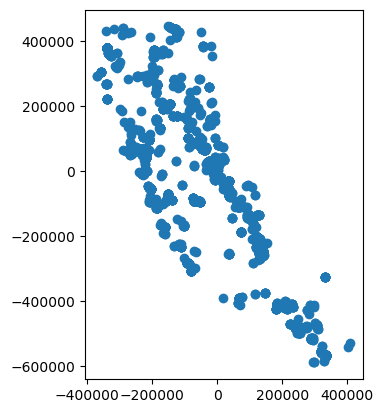

In [7]:
fire_with_plants_joined.plot()

array([[<Axes: title={'center': 'observation_date'}>]], dtype=object)

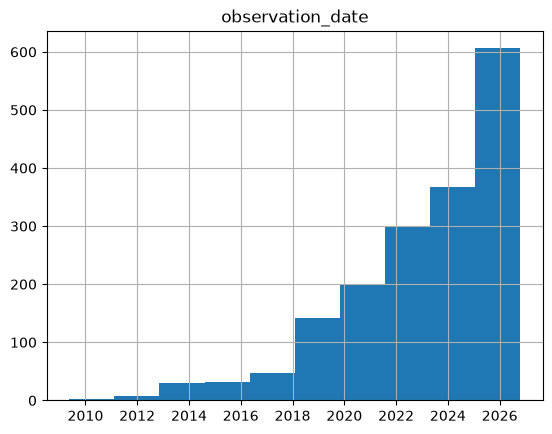

In [ ]:
fire_plants.hist("observation_date");

In [26]:
prescribed_burns_cleaned["year"].value_counts()

year
2023    1190
2019    1054
2025     982
2024     949
2020     732
2021     724
2022     634
2018     497
2017     258
2011     246
2010     221
2009     216
2013     170
2015     165
2012     121
2014     108
2016      78
Name: count, dtype: int64